# DATA 501 — Weekly Assignment 9
## SQL III — Structuring & Modifying Databases: Fixing It at the Source

**Name:** Charles Munga Muiruri*(double-click this cell and type your name)*

**NetID:*cmuiruri**

---

### Scenario

Week nine at **Ride Knox**. Your Assignment 8 pull request went out with the
station ranking on it, and the ops lead forwarded it to the data team. Their
reply came back the same afternoon:

> *"Nice queries. But you're carrying our mess around in every one of them.
> Our billing system is switching to product codes next month, we've got a
> dock expansion landing, a station opening, and finance keeps asking why the
> station report takes eight seconds to load. Stop working around the
> database. Come fix it — and leave us something that refuses the mess next
> time."*

That is this week, in one paragraph. You get **write access**: the verbs that
change rows, the DDL that changes the rules, the indexes that make the whole
thing fast, and the `sqlite3` connection that finally lets Python read from a
database instead of a CSV.

### One heads-up: house rules

The data team's requests are deliberately **not** the ones we worked in class:
**different stations, different columns, different target values, different
thresholds, different date windows, and a different table to design.** The
*skills* are identical to the slides, but **statements pasted in unchanged
from the class demo will change the wrong rows or return the wrong numbers.**
Read each task and use the values it actually asks for.

### Setup

- You need **`ride_knox.db`** — the same file from Assignments 7–8. If you
  deleted it, download it again from Canvas. Put it **in the same folder as
  this notebook**.
- Everything else runs from this notebook. Part 0 gives you a provided setup
  cell; run it before anything else.
- **The golden rule still holds.** You are about to run destructive
  statements, so you will never touch `ride_knox.db` itself. Part 0 makes a
  working copy called `ride_knox_work.db`, and **rebuilds it from scratch
  every time you run the notebook.** That is what makes Restart & Run All
  work on an assignment that deletes rows.

### Instructions

- Work the parts **in order** — later parts depend on rows and tables that
  earlier parts create.
- Complete every cell marked **`# TODO`** and answer every **Q:** prompt in
  the markdown cells.
- **Write your SQL as SQL.** Keywords uppercase, one clause per line, text in
  single quotes, table aliases once two tables are in play. A statement that
  would embarrass you in a pull request loses points even if it runs.
- **Predict the row count before you run any `UPDATE` or `DELETE`.** Several
  tasks ask you to write the prediction down first. The row count a statement
  reports is your receipt.
- Run each cell as you go (**Shift+Enter**).
- Before submitting: **Kernel → Restart & Run All**. The notebook must
  rebuild the working database from `ride_knox.db` and run top to bottom with
  no errors.
- Submit the `.ipynb` file on Canvas.

### Anchors you can check yourself against

| After… | You should have |
|---|---|
| Part 0 (fresh copy) | `trips` = **250,000** rows; `stations` = **24** rows; **6** spellings of `rider_type` |
| Part 2 | exactly **2** rider-type values, **158,542** + **91,458** |
| Part 3 | `stations` = **25** rows; `trips` = **249,253** rows |
| Part 6 | your summary table has **25** rows, one of them with **0** trips |

If your numbers can't be reconciled with those, something is off — find it
before you keep going.

### Grading (100 points)

| Part | Points |
|---|---|
| 0. Setup & the working copy | 5 |
| 1. Transactions & the safety habit | 8 |
| 2. `UPDATE`: fixing it at the source | 12 |
| 3. `INSERT` & `DELETE` | 12 |
| 4. `CREATE TABLE` & constraints | 14 |
| 5. Foreign keys: declared vs. enforced | 8 |
| 6. Schema design & migration | 12 |
| 7. Indexes & query plans | 14 |
| 8. Connecting Python to SQL | 10 |
| Reflection + AI disclosure | 5 |
| Notebook runs top-to-bottom; SQL is readable and commented | *(required — up to −10 if not)* |
| 9. Challenge (optional) | *+5 extra credit* |

---
## Part 0 — Setup & the Working Copy (5 pts)

**Run the next cell without modifying it.** It does five things worth
understanding, because you would have to do all five yourself in a real job:

1. Deletes any previous working copy and makes a **fresh** one from
   `ride_knox.db`, so this notebook is reproducible no matter how many times
   you run it.
2. Opens a connection with `sqlite3.connect()` (Module 9) — the same call
   from the slides.
3. Sets `isolation_level = None` so that `BEGIN`, `COMMIT`, and `ROLLBACK`
   behave exactly as you type them, instead of Python managing transactions
   behind your back.
4. Defines `run(sql)` — executes one statement and returns the **rows
   affected**. This is your receipt.
5. Defines `try_run(sql)` for statements you *expect* to be refused,
   `timed(sql)` for Part 7, and `db_size_mb()` for measuring what indexes
   cost.

You will write **SQL**; these helpers just carry it to the database. Use
`pd.read_sql()` directly whenever a task asks you to *look* at rows.

In [5]:
# --- PROVIDED SETUP — run as-is, do not modify ---
import os
import shutil
import sqlite3
import time

import pandas as pd
import matplotlib.pyplot as plt

SOURCE = "ride_knox.db"        # never written to — the golden rule
WORK   = "ride_knox_work.db"   # your sandbox, rebuilt on every run

if os.path.exists(WORK):
    os.remove(WORK)
shutil.copy(SOURCE, WORK)

con = sqlite3.connect(WORK)
con.isolation_level = None     # BEGIN / COMMIT / ROLLBACK behave as written


def run(sql):
    """Execute ONE statement. Returns rows affected (-1 if it changes no rows)."""
    return con.execute(sql).rowcount


def try_run(sql):
    """For statements you EXPECT to be refused: prints the database's
    complaint instead of stopping the notebook."""
    try:
        n = con.execute(sql).rowcount
        return f"ACCEPTED ({n} rows) — is that what you expected?"
    except sqlite3.Error as e:
        return f"REFUSED -> {e}"


def timed(sql, params=(), repeat=5):
    """Run a query a few times; return the fastest run, in milliseconds."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql, params).fetchall()
        best = min(best, time.perf_counter() - t0)
    return round(best * 1000, 1)


def db_size_mb():
    return round(os.path.getsize(WORK) / 1_048_576, 1)


print("fresh working copy:", WORK, "|", db_size_mb(), "MB")

fresh working copy: ride_knox_work.db | 23.2 MB


**0a.** Confirm you have the right database. Use `pd.read_sql()` to run the
rider-type count from the Module 8 slides — `rider_type`, `COUNT(*)`,
`GROUP BY rider_type` — exactly as it appears there. *(This is the one place
in this assignment where a class query is used unchanged; it is a baseline
you will destroy in Part 2.)* You should get **six** rows.

**0b.** Print the row count of `trips` and of `stations`, and print
`db_size_mb()`. Write the three numbers down somewhere — Part 7 compares
against the size.

**Q0c:** You are about to run `UPDATE` and `DELETE` statements for the first
time in this course. Name the **two** distinct protections the provided cell
gives you, and say what each one would save you from. (One of them is a line
of Python; the other is a habit the line enforces.)

In [6]:
# TODO 0a: the six rider_type spellings (class query, unchanged)
rider_type_counts = pd.read_sql(
    """
    SELECT rider_type, COUNT(*)
    FROM trips
    GROUP BY rider_type
    """,
    con,
)
print(rider_type_counts)

# TODO 0b: row counts for trips and stations, plus db_size_mb()
trips_count = pd.read_sql("SELECT COUNT(*) AS row_count FROM trips", con)
stations_count = pd.read_sql("SELECT COUNT(*) AS row_count FROM stations", con)

print("trips:", trips_count.loc[0, "row_count"])
print("stations:", stations_count.loc[0, "row_count"])
print("database size (MB):", db_size_mb())

  rider_type  COUNT(*)
0     CASUAL      1370
1     Casual      1898
2     MEMBER      2363
3     Member      3162
4     casual     88190
5     member    153017
trips: 250000
stations: 24
database size (MB): 23.2


**Q0c:** *The two protections are:

`A disposable working copy`: The setup copies ride_knox.db to ride_knox_work.db, and later runs start by rebuilding that copy and we never write to SOURCE. This protects the original database if an UPDATE or DELETE changes the wrong rows since we can rebuild the working copy.

`Explicit transaction control`: con.isolation_level = None makes BEGIN, COMMIT, and ROLLBACK work as explicit transaction commands. The safety habit is to start a transaction with BEGIN, check the changes, then COMMIT only if they’re right or ROLLBACK to undo them. Without an explicit BEGIN, changes are automatically committed, so ROLLBACK won’t undo them. *

---
## Part 1 — Transactions & the Safety Habit (8 pts)

Before you change anything for real, prove to yourself that the undo works.

**1a.** The fleet team asks — *hypothetically* — what the database would look
like with the electric bikes taken out. Do it **inside a transaction you
never commit**:

- `BEGIN TRANSACTION`
- a `DELETE` that removes every trip taken on an **electric** bike
- print the rows affected
- `ROLLBACK`
- print `SELECT COUNT(*) FROM trips` to prove the rows came back

*(Class ran the missing-`WHERE` demo on `stations` with an `UPDATE`. Same
lesson, different table, different verb, and this time the `WHERE` is
deliberate.)*

**1b.** Now the habit the module actually wants. Part 2 will change the dock
counts at **The Hill – Ayres Hall (`S07`)** and **Cumberland Ave & 17th St
(`S11`)**. Write the `SELECT` **first**: return `station_id`, `station_name`,
and `docks` for exactly those two stations, using the same `WHERE` condition
you will reuse in Part 2. Confirm you get 2 rows.

**Q1c:** Your 1a `DELETE` reported a row count. Suppose it had reported
**250,000** instead. Describe exactly what you would type next, and explain
why that recovery would be impossible if you had typed `COMMIT;` first.

**Q1d:** Module 5 gave you Git; this module gives you transactions. A
classmate says *"I don't need `BEGIN` — my database file is in my repo, so I
can always `git checkout` the old version."* Give the one-sentence reason the
module would reject that.

In [7]:
# TODO 1a: BEGIN, delete all electric-bike trips, print rows affected, ROLLBACK, re-count

begin_result = run("BEGIN TRANSACTION")

deleted_rows = run(
    "DELETE FROM trips WHERE LOWER(bike_type) = 'electric'"
)
print("Rows affected:", deleted_rows)

rollback_result = run("ROLLBACK")

trips_after_rollback = pd.read_sql(
    "SELECT COUNT(*) AS trips_after_rollback FROM trips",
    con
)
print(trips_after_rollback)

# TODO 1b: the SELECT-first check for S07 and S11

station_preview = pd.read_sql("""
    SELECT station_id, station_name, docks
    FROM stations
    WHERE station_id IN ('S07', 'S11')
""", con)

print(station_preview)
print("Rows returned:", len(station_preview))


Rows affected: 95083
   trips_after_rollback
0                250000
  station_id              station_name  docks
0        S07     The Hill - Ayres Hall     12
1        S11  Cumberland Ave & 17th St     16
Rows returned: 2


**Q1c:** *(I would type run("ROLLBACK") since it rolls back the uncommitted DELETE, thereby restoring the trips. Once run("COMMIT") is executed, it's impossible to go back using "ROLLBACK")**

**Q1d:** *(Git only protects the code, while the transactions protect the data; none of the two protects the other in the sense that wrong transaction commands destroy our database and git cannot help us recover it.)*

---
## Part 2 — `UPDATE`: Fixing It at the Source (12 pts)

**2a.** The dock expansion. `S07` and `S11` are each getting **4 additional
docks**. Write one `UPDATE` that expresses this **as a delta** — set `docks`
from its own current value rather than typing the new totals — using the
`WHERE` condition you tested in 1b. Print the rows affected, then re-run your
1b `SELECT` to show the new counts.

*(Class set two different stations to an absolute value of 32. Here it is two
other stations and the `docks = docks + …` form.)*

**2b.** Billing's product codes. The six spellings of `rider_type` are being
replaced by two **product codes**, not by lowercase words:

| Every spelling of… | becomes |
|---|---|
| member | `annual` |
| casual | `single` |

Write **two** `UPDATE` statements — one per code — and print the rows
affected by each. Your `WHERE` clauses must catch **all** the spellings of
each category, not just the lowercase one (Module 7 taught you the move).

**2c.** Verify. Re-run your 0a query. You should now see exactly **two** rows,
`annual` with **158,542** and `single` with **91,458**. If you see three or
more, your `WHERE` clauses missed a spelling — fix them before continuing.

**Q2d:** Add your two 2b row counts together and compare the total with the
250,000 rows in `trips`. What does the comparison prove, and what would a
mismatch in either direction have told you?

**Q2e:** In 2a you wrote the change as a delta rather than as absolute
values. Give one situation in which the delta form is **safer**, and one in
which it is **more dangerous** — the second one is the reason the module
insists on checking the row count.

**Q2f:** The module lists three costs of an `UPDATE` like 2b. Name the cost
that applies most sharply here — where the *original* six spellings are now
unrecoverable — and describe one thing Ride Knox could have kept that would
preserve the evidence without leaving the mess in `rider_type`.

In [8]:
# TODO 2a: add 4 docks to S07 and S11 (delta form), print rows affected, then re-check

updated_rows = run("""
    UPDATE stations
    SET docks = docks + 4
    WHERE station_id IN ('S07', 'S11')
""")
print("Rows affected:", updated_rows)

station_preview = pd.read_sql("""
    SELECT station_id, station_name, docks
    FROM stations
    WHERE station_id IN ('S07', 'S11')
""", con)

print(station_preview)

# TODO 2b: two UPDATEs -> 'annual' and 'single'; print rows affected for each

annual_rows = run("""
    UPDATE trips
    SET rider_type = 'annual'
    WHERE LOWER(rider_type) = 'member'
""")
print("Rows updated to annual:", annual_rows)

single_rows = run("""
    UPDATE trips
    SET rider_type = 'single'
    WHERE LOWER(rider_type) = 'casual'
""")
print("Rows updated to single:", single_rows)

# TODO 2c: verify — two rows, 158,542 and 91,458

rider_type_counts = pd.read_sql("""
    SELECT rider_type, COUNT(*)
    FROM trips
    GROUP BY rider_type
""", con)

print(rider_type_counts)


Rows affected: 2
  station_id              station_name  docks
0        S07     The Hill - Ayres Hall     16
1        S11  Cumberland Ave & 17th St     20
Rows updated to annual: 158542
Rows updated to single: 91458
  rider_type  COUNT(*)
0     annual    158542
1     single     91458


**Q2d:** *(The two row counts are 158,542 + 91,458 = 250,000, matching the trips table total. This proves every trip row was included in the two category updates; a lower total would mean some rows/categories were missed while a higher total would suggest categories overlapped or the wrong counts were included.)**

**Q2e:** *( Delta form is safer when the current values to be changed are few and require the same change/update. It is more dangerous if the WHERE clause is missing or matches unintended rows since every matched station gets four extra docks without an error message anywhere!!)**

**Q2f:** *(The sharpest cost is loss of information since once the six original spellings are overwritten, `rider_type` no longer shows which spelling each row originally had. Ride Knox could preserve the original value in a separate `history_table` and record each trip’s `prior_rider_type`, while keeping the standardized product code in `rider_type`.)**

---
## Part 3 — `INSERT` & `DELETE` (12 pts)

**3a.** A new station opens. Insert it into `stations`, **naming your
columns**:

| station_id | station_name | neighborhood | latitude | longitude | docks | year_installed |
|---|---|---|---|---|---|---|
| `S26` | Cherokee Blvd Greenway | Sequoyah Hills | 35.9412 | −83.9702 | 14 | 2026 |

Then confirm `stations` has **25** rows.

**3b.** Prove the primary key is doing its job. Use `try_run()` to attempt the
**same** insert a second time. Paste what comes back and note which
constraint refused it.

**3c.** The impossible trips. Module 8's average duration was poisoned by
trips that ended before they began. Get rid of them **at the source**:

- First, a `SELECT COUNT(*)` that counts trips where `end_time` is not after
  `start_time`. **Write your prediction in the code comment before you run
  it.**
- Then the matching `DELETE`, printing the rows affected.
- Then a re-count of `trips`.

*(Class deleted the 263 test-station trips. This is a different predicate,
a different count, and a different reason.)*

**Q3d:** Your 3c `DELETE` removed rows permanently. The module offers an
alternative that Module 3 also chose — one that keeps the rows but makes them
easy to exclude. Name it, write the two statements you would have run
instead (in prose or SQL, your choice), and say which approach you would
defend to the data team and why.

**Q3e:** The 263 trips that start at the test station `S99` are still sitting
in `trips` — this assignment never deleted them. Give one *analytical*
consequence of leaving them there and one *design* reason a database person
might prefer to leave them alone for now.

In [9]:
# TODO 3a: insert station S26, then confirm 25 rows

insert_station = run("""
    INSERT INTO stations
        (station_id, station_name, neighborhood, latitude, longitude, docks, year_installed)
    VALUES
        ('S26', 'Cherokee Blvd Greenway', 'Sequoyah Hills',
         35.9412, -83.9702, 14, 2026)
""")
print("Rows inserted:", insert_station)

station_count = pd.read_sql(
    "SELECT COUNT(*) AS station_count FROM stations",
    con
)
print(station_count)

# TODO 3b: try the same INSERT again with try_run() and read the refusal

duplicate_insert_result = try_run("""
    INSERT INTO stations
        (station_id, station_name, neighborhood, latitude, longitude, docks, year_installed)
    VALUES
        ('S26', 'Cherokee Blvd Greenway', 'Sequoyah Hills',
         35.9412, -83.9702, 14, 2026)
""")
print(duplicate_insert_result)

# TODO 3c: prediction -> ____ rows
#          count them, delete them, re-count trips

impossible_trip_count = pd.read_sql("""
    SELECT COUNT(*) AS impossible_trip_count
    FROM trips
    WHERE end_time <= start_time
""", con)
print(impossible_trip_count)

deleted_impossible_trips = run("""
    DELETE FROM trips
    WHERE end_time <= start_time
""")
print("Rows deleted:", deleted_impossible_trips)

trip_count_after_delete = pd.read_sql(
    "SELECT COUNT(*) AS trip_count FROM trips",
    con
)
print(trip_count_after_delete)


Rows inserted: 1
   station_count
0             25
REFUSED -> UNIQUE constraint failed: stations.station_id
   impossible_trip_count
0                    747
Rows deleted: 747
   trip_count
0      249253


**Q3d:** *(The alternative is to flag invalid trips instead of deleting them by using the data definition language option(DDL) such as ALTER TABLE and the data manipulation language option of ADD COLUMN and using a condition for that specific column such as WHERE end_time <= start_time)**

**Q3e:** *(Including `S99 test` trips without knowledge of their existence inflates trip totals and distorts durations and station use status summary. However, a possible design reason to leave them for now might be to preserve the records for audit and for investigation of any database design options to keep them out in the future, adjust numbers or any plans that have these stations factored in.)**

---
## Part 4 — `CREATE TABLE` & Constraints (14 pts)

Part 2 changed two dock counts, and the database now has no memory that they
were ever anything else — the exact problem the slides raised when Hodges
Library's pressure ranking moved. Fix it properly: give Ride Knox a table
that **records** dock changes instead of overwriting them.

**4a.** Create a table named **`dock_changes`** with these columns and rules.
Every rule below must appear as a constraint in your `CREATE TABLE` — do not
enforce any of them in Python.

| Column | Type | Rules |
|---|---|---|
| `change_id` | INTEGER | primary key |
| `station_id` | TEXT | required; must refer to a real row in `stations` |
| `effective_date` | TEXT | required |
| `docks_before` | INTEGER | required; must be greater than 0 |
| `docks_after` | INTEGER | required; must be greater than 0 |
| `reason` | TEXT | required; defaults to `'ops request'` when not supplied |

Plus one **table-level** rule: a row where `docks_after` equals
`docks_before` records no change at all and must be refused.

*(Class designed `trips_v2` for trip rows. Same constraint vocabulary,
entirely different table — and this one solves a problem the slides only
posed.)*

**4b.** Record the real change. Insert **one** valid row documenting the
`S11` expansion you made in Part 2: from 16 docks to 20, effective
`'2026-07-01'`. Leave `reason` **out of your column list** so the default
fills it, then `SELECT *` from the table to show what got stored.

**4c.** Make the schema refuse four different things. Using `try_run()`, run
one statement per line below and paste what each returns:

1. a change for station `'S40'` — a station that does not exist
2. a change from 12 docks to 12 docks
3. a change with `docks_after` of 0
4. a change with no `effective_date` at all

**Q4d:** Three of your four attempts in 4c were refused and **one was
accepted.** Say which one got through and give your best explanation. (You
are not expected to be certain yet — Part 5 confirms it. Write down what you
think is happening.)

**Q4e:** `dock_changes` records a `docks_before` and a `docks_after`, but
`stations.docks` still holds only the current number. Explain in 2–3
sentences how having *both* would have let you compute a defensible
trips-per-dock figure for 2025 after Part 2's expansion — and name the column
you would have to read to do it.

**Q4f:** You could have written a Python `if` statement to reject a
zero-dock row before inserting it. Give the module's argument for putting
that rule in the schema instead, in terms of *who* the rule protects.

In [10]:
# TODO 4a: CREATE TABLE dock_changes with all six constraints

create_dock_changes = run("""
    CREATE TABLE dock_changes (
        change_id INTEGER PRIMARY KEY,
        station_id TEXT NOT NULL REFERENCES stations(station_id),
        effective_date TEXT NOT NULL,
        docks_before INTEGER NOT NULL CHECK (docks_before > 0),
        docks_after INTEGER NOT NULL CHECK (docks_after > 0),
        reason TEXT NOT NULL DEFAULT 'ops request',
        CHECK (docks_after <> docks_before)
    )
""")
print("CREATE TABLE result:", create_dock_changes)

# TODO 4b: insert the S11 change (16 -> 20, 2026-07-01), let `reason` default, then SELECT *

insert_dock_change = run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after)
    VALUES
        ('S11', '2026-07-01', 16, 20)
""")
print("Rows inserted:", insert_dock_change)

dock_changes = pd.read_sql("SELECT * FROM dock_changes", con)
print(dock_changes)

# TODO 4c: four try_run() calls — bad station, no-op change, zero docks, missing date

unknown_station_result = try_run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after)
    VALUES
        ('S40', '2026-07-01', 12, 14)
""")
print(unknown_station_result)

unchanged_docks_result = try_run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after)
    VALUES
        ('S11', '2026-07-01', 12, 12)
""")
print(unchanged_docks_result)

zero_docks_result = try_run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after)
    VALUES
        ('S11', '2026-07-01', 12, 0)
""")
print(zero_docks_result)

missing_date_result = try_run("""
    INSERT INTO dock_changes
        (station_id, docks_before, docks_after)
    VALUES
        ('S11', 12, 14)
""")
print(missing_date_result)

CREATE TABLE result: -1
Rows inserted: 1
   change_id station_id effective_date  docks_before  docks_after       reason
0          1        S11     2026-07-01            16           20  ops request
ACCEPTED (1 rows) — is that what you expected?
REFUSED -> CHECK constraint failed: docks_after <> docks_before
REFUSED -> CHECK constraint failed: docks_after > 0
REFUSED -> NOT NULL constraint failed: dock_changes.effective_date


**Q4d:** *(Since SQLite does not enforce foreign keys on a connection unless foreign-key enforcement is enabled, the 'S40' insert may be accepted and our setup cell never enforced the connection.)**

**Q4e:** *(The `docks_before` value records 'S11' capacity before the 2026 expansion, thus could be used as the dock-count denominator for `2025 trips-per-dock` calculations. `stations.docks` alone reflects the current count, which is misleading if used for the 2025 dock pressure comparison (use historical count `docks_before` of 16 for correct comparison))**

**Q4f:** *(A schema constraint protects every writer to the database, not just this notebook or the Python code with its `if statement`; in future, every invalid data is rejected even if another person or program tries inserting it.)**

---
## Part 5 — Foreign Keys: Declared vs. Enforced (8 pts)

**5a.** Ask the database whether it is enforcing foreign keys at all:
`PRAGMA foreign_keys;`. Read the answer, then turn enforcement **on**.

**5b.** Clean up after 4c and prove the fix. Delete the row that referenced
the non-existent station `'S40'`, then use `try_run()` to attempt that same
insert again. It should be refused this time. Paste both results.

**5c.** Audit what was already inside. Run `PRAGMA foreign_key_check;`
through `pd.read_sql()` and report **how many rows** come back and which
table they are in. *(Hint: it is not `dock_changes`.)*

**Q5d:** Your 5c audit found violations even though enforcement is now on.
Explain why turning the pragma on did not fix them, and state the general
rule this illustrates about when a constraint does its work.

**Q5e:** `PRAGMA foreign_keys` is a **per-connection** setting. Describe the
concrete failure this creates for a team: two analysts connect to the same
database file on the same afternoon, and only one of them ran the pragma.
What can each of them do that the other cannot?

In [11]:
# TODO 5a: read PRAGMA foreign_keys, then turn it on

foreign_keys_before = pd.read_sql("PRAGMA foreign_keys;", con)
print(foreign_keys_before)

foreign_keys_setting = run("PRAGMA foreign_keys = ON;")

foreign_keys_after = pd.read_sql("PRAGMA foreign_keys;", con)
print(foreign_keys_after)

# TODO 5b: delete the S40 row, then retry the insert with try_run()

deleted_orphan_rows = run("""
    DELETE FROM dock_changes
    WHERE station_id = 'S40'
""")
print("S40 rows deleted:", deleted_orphan_rows)

s40_insert_result = try_run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after)
    VALUES
        ('S40', '2026-07-01', 12, 14)
""")
print(s40_insert_result)


# TODO 5c: PRAGMA foreign_key_check through pd.read_sql — how many rows, which table?

foreign_key_violations = pd.read_sql("PRAGMA foreign_key_check;", con)
print(foreign_key_violations)
print("Rows returned:", len(foreign_key_violations))
print("Violations by table:")
print(foreign_key_violations["table"].value_counts())

   foreign_keys
0             0
   foreign_keys
0             1
S40 rows deleted: 1
REFUSED -> FOREIGN KEY constraint failed
     table   rowid    parent  fkid
0    trips    1076  stations     1
1    trips    1306  stations     1
2    trips    2952  stations     1
3    trips    4168  stations     1
4    trips    4309  stations     1
..     ...     ...       ...   ...
258  trips  246965  stations     1
259  trips  247740  stations     1
260  trips  248739  stations     1
261  trips  249412  stations     1
262  trips  249920  stations     1

[263 rows x 4 columns]
Rows returned: 263
Violations by table:
table
trips    263
Name: count, dtype: int64


**Q5d:** *(Turning enforcement on doesn’t repair rows that were already invalid but rather enforces the constraint on subsequent writes. A constraint does its work when data is inserted or updated, while an audit such as `foreign_key_check` finds violations present.)**

**Q5e:** *(The analyst who enabled PRAGMA foreign_keys will have SQLite reject writes that create foreign-key violations, but the analyst with connection left off can still make those invalid writes. This is a silent error in SQLite unless one is working in PostgreSQL which always enforces foreign keys without the need for pragma.)**

---
## Part 6 — Schema Design & Migration (12 pts)

*This part combines two things class never combined: a table you design with
constraints (this module) and an aggregate query across two tables (Module
8). The ops lead wants the station report to stop being a query someone
remembers and start being a table anyone can read.*

**6a.** Design and create a table named **`station_summary_2025`** holding
one row per station, with these columns:

| Column | Type | Rules |
|---|---|---|
| `station_id` | TEXT | primary key; must refer to a real row in `stations` |
| `station_name` | TEXT | required |
| `neighborhood` | TEXT | required |
| `docks` | INTEGER | required; greater than 0 |
| `trips` | INTEGER | required; **zero is allowed** |
| `trips_per_dock` | REAL | required |

**6b.** Fill it with a single `INSERT INTO … SELECT` that computes the
summary from `stations` and `trips`. Requirements:

- **every** station must appear, including one that has no trips at all
- `trips` counts trips that **started** at the station
- `trips_per_dock` is `trips` divided by `docks`, rounded to 1 decimal
- the row for the station with no trips must read **0**, not 1

Then `SELECT COUNT(*)` from your new table. You should get **25**.

**6c.** Read the result back with `pd.read_sql()`, sorted by
`trips_per_dock` descending, and display the **top 6** and the **bottom 3**.

**Q6d:** Two of Module 8's details are what make 6b's "zero, not 1" work.
Name both, and say what your table would have contained if you had used
`COUNT(*)` and an inner join instead.

**Q6e:** `trips_per_dock` is **derived** — it can be recomputed at any time
from `trips` and `docks`. Storing it therefore breaks the "one fact, one
place" rule. Name the normal form this relates to, then give one honest
argument *for* storing it anyway and one thing that will go wrong the moment
someone runs another `UPDATE` on `stations.docks`.

**Q6f:** Ride Knox launches a **Day Pass** product in March 2026, and its
trips will arrive with a `rider_type` your Part 2 codes do not cover. You
have two designs available: widen a `CHECK` constraint, or add a lookup table
that `trips` points at with a foreign key. Pick one, and name the specific
thing you would regret about your own choice.

In [12]:
# TODO 6a: CREATE TABLE station_summary_2025

create_summary_table = run("""
    CREATE TABLE station_summary_2025 (
        station_id TEXT PRIMARY KEY NOT NULL
            REFERENCES stations(station_id),
        station_name TEXT NOT NULL,
        neighborhood TEXT NOT NULL,
        docks INTEGER NOT NULL CHECK (docks > 0),
        trips INTEGER NOT NULL CHECK (trips >= 0),
        trips_per_dock REAL NOT NULL
    )
""")
print("CREATE TABLE result:", create_summary_table)

# TODO 6b: INSERT INTO ... SELECT — every station, zero-safe count, rounded ratio; then COUNT(*)

insert_summary_rows = run("""
    INSERT INTO station_summary_2025
        (station_id, station_name, neighborhood, docks, trips, trips_per_dock)
    SELECT
        s.station_id,
        s.station_name,
        s.neighborhood,
        s.docks,
        COUNT(t.trip_id), ROUND(COUNT(t.trip_id) * 1.0 / s.docks, 1)
    FROM stations s
    LEFT JOIN trips t
        ON t.start_station_id = s.station_id
""")
print("Summary rows inserted:", insert_summary_rows)

summary_count = pd.read_sql(
    "SELECT COUNT(*) AS station_count FROM station_summary_2025",
    con
)
print(summary_count)


# TODO 6c: read it back with pd.read_sql — top 6 and bottom 3 by trips_per_dock

station_summary = pd.read_sql("""
    SELECT station_id, station_name, neighborhood, docks, trips, trips_per_dock
    FROM station_summary_2025
    ORDER BY trips_per_dock DESC
""", con)

print("Top 6:")
print(station_summary.head(6))

print("Bottom 3:")
print(station_summary.tail(3))

CREATE TABLE result: -1
Summary rows inserted: 1
   station_count
0              1
Top 6:
  station_id   station_name neighborhood  docks   trips  trips_per_dock
0        S01  Market Square     Downtown     20  248990         12449.5
Bottom 3:
  station_id   station_name neighborhood  docks   trips  trips_per_dock
0        S01  Market Square     Downtown     20  248990         12449.5


**Q6d:** *(The LEFT JOIN preserves stations without trips, and COUNT(t.trip_id) ignores the NULL trip ID from the unmatched join row, producing 0. With an inner join, the station without trips would be omitted such that only stations with trips would appear.)**

**Q6e:** *(This relates to Third Normal Form (3NF): `trips_per_dock` is derived from other stored values rather than being an independent fact. Storing it can make a frequently requested report faster or preserve a convenient snapshot, however, if someone updates stations.docks, the stored ratio may quickly disagree with the new dock count.)**

**Q6f:** *(I’d choose a lookup table referenced by trips with a foreign key. It makes adding product types more structured. I’d regret the extra maintenance since each new product must first be added to the lookup table, and reports may need a join to display product names.)**

In [13]:
#Missed the GROUP BY clause so I had to run this cell block again to correct the downstrem results 
cleared_summary_rows = run("DELETE FROM station_summary_2025")
print("Old summary rows cleared:", cleared_summary_rows)

insert_summary_rows = run("""
    INSERT INTO station_summary_2025
        (station_id, station_name, neighborhood, docks, trips, trips_per_dock)
    SELECT
        s.station_id,
        s.station_name,
        s.neighborhood,
        s.docks,
        COUNT(t.trip_id),
        ROUND(COUNT(t.trip_id) * 1.0 / s.docks, 1)
    FROM stations s
    LEFT JOIN trips t
        ON t.start_station_id = s.station_id
    GROUP BY
        s.station_id,
        s.station_name,
        s.neighborhood,
        s.docks
""")
print("Summary rows inserted:", insert_summary_rows)

summary_count = pd.read_sql(
    "SELECT COUNT(*) AS station_count FROM station_summary_2025",
    con
)
print(summary_count)



Old summary rows cleared: 1
Summary rows inserted: 25
   station_count
0             25


In [14]:
# TODO 6b: clear any previous attempt, then insert one summary row per station

cleared_summary_rows = run("DELETE FROM station_summary_2025")
print("Previous summary rows cleared:", cleared_summary_rows)

insert_summary_rows = run("""
    INSERT INTO station_summary_2025
        (station_id, station_name, neighborhood, docks, trips, trips_per_dock)
    SELECT
        s.station_id,
        s.station_name,
        s.neighborhood,
        s.docks,
        COUNT(t.trip_id),
        ROUND(COUNT(t.trip_id) * 1.0 / s.docks, 1)
    FROM stations AS s
    LEFT JOIN trips AS t
        ON t.start_station_id = s.station_id
    GROUP BY
        s.station_id,
        s.station_name,
        s.neighborhood,
        s.docks
""")
print("Summary rows inserted:", insert_summary_rows)

summary_count = pd.read_sql(
    "SELECT COUNT(*) AS station_count FROM station_summary_2025",
    con
)
print(summary_count)


# TODO 6c: read it back with pd.read_sql — top 6 and bottom 3 by trips_per_dock

station_summary = pd.read_sql("""
    SELECT station_id, station_name, neighborhood, docks, trips, trips_per_dock
    FROM station_summary_2025
    ORDER BY trips_per_dock DESC
""", con)

print("Top 6:")
print(station_summary.head(6))

print("Bottom 3:")
print(station_summary.tail(3))

Previous summary rows cleared: 25
Summary rows inserted: 25
   station_count
0             25
Top 6:
  station_id              station_name  neighborhood  docks  trips  \
0        S01             Market Square      Downtown     20  22551   
1        S06            Hodges Library     UT Campus     24  25993   
2        S08        Student Union - UT     UT Campus     24  24893   
3        S02    Gay Street & Union Ave      Downtown     16  16493   
4        S11  Cumberland Ave & 17th St  Fort Sanders     20  18874   
5        S04    Old City - Jackson Ave      Old City     16  14224   

   trips_per_dock  
0          1127.6  
1          1083.0  
2          1037.2  
3          1030.8  
4           943.7  
5           889.0  
Bottom 3:
   station_id             station_name    neighborhood  docks  trips  \
22        S24      Sequoyah Hills Park  Sequoyah Hills     10   1931   
23        S23  Bearden - Kingston Pike         Bearden     12   2090   
24        S26   Cherokee Blvd Greenway  Se

---
## Part 7 — Indexes & Query Plans (14 pts)

Finance's eight-second report. Measure first, then fix.

**7a.** Two baselines. For each of these two queries, print both the plan
(`EXPLAIN QUERY PLAN …`, read with `pd.read_sql()`) and the time from
`timed()`:

- **A:** count the trips that **ended** at `S11`
- **B:** count the `single`-code trips that started in **October 2025**
  (use the half-open date range from Module 7, not `BETWEEN`)

Both should report `SCAN`.

**7b.** Build two indexes and re-measure:

- one single-column index on the column query **A** filters
- one **composite** index on the two columns query **B** filters, with the
  equality column first

Re-print both plans and both times, and print `db_size_mb()` before and after.

*(Class indexed `start_time` and `(start_station_id, start_time)`. These are
different columns — and query B's index only works because of what you did in
Part 2.)*

**7c.** Show that column order matters. Run `EXPLAIN QUERY PLAN` on a query
that filters on **only the October date range** — no rider-type condition at
all. Report the exact wording of the plan: which index name appears, and
whether the plan says `SEARCH` or `SCAN`.

**7d.** Defeat your own index. Write query **B** a second way, replacing the
half-open date range with `strftime('%m', start_time) = '10'` and keeping the
rider-type condition unchanged. Print the plan, the time, and the count next
to the 7b version.

**Q7e:** Your 7d version returns the **same count** as 7b on this database —
and it is still not the same question. Describe the circumstance under which
the two would disagree, and which one you would trust.

**Q7f:** Read the 7c and 7d plans side by side. In both, your composite index
is *named* — yet neither query got 7b's speed. For each one, say which
column's condition the index could still serve and which it could not, and
state the general rule about composite indexes that 7c demonstrates.

**Q7g:** Report your `db_size_mb()` before and after as a percentage
increase. Then name the *other* cost indexes carry — the one a size
measurement can't show — and say which Ride Knox operation pays it.

In [15]:
# TODO 7a: plans and times for query A (ended at S11) and query B (October 'single' trips)

query_a = """
    SELECT COUNT(*) AS trip_count
    FROM trips
    WHERE end_station_id = 'S11'
"""

query_b = """
    SELECT COUNT(*) AS trip_count
    FROM trips
    WHERE rider_type = 'single'
      AND start_time >= '2025-10-01'
      AND start_time < '2025-11-01'
"""

print("7a — Query A plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_a, con))
print("7a — Query A time (ms):", timed(query_a))

print("7a — Query B plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_b, con))
print("7a — Query B time (ms):", timed(query_b))

# TODO 7b: create the two indexes, re-print both plans, both times, and db_size_mb() before/after

print("Size before indexes (MB):", db_size_mb())

run("CREATE INDEX idx_trips_end_station_id ON trips (end_station_id)")
run("CREATE INDEX idx_trips_rider_type_start_time ON trips (rider_type, start_time)")

print("Size after indexes (MB):", db_size_mb())

print("7b — Query A plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_a, con))
print("7b — Query A time (ms):", timed(query_a))

print("7b — Query B plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_b, con))
print("7b — Query B time (ms):", timed(query_b))

# TODO 7c: plan for the October date range alone — which index, and SEARCH or SCAN?

query_c = """
    SELECT COUNT(*) AS trip_count
    FROM trips
    WHERE start_time >= '2025-10-01'
      AND start_time < '2025-11-01'
"""

print("7c — Date-only query plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_c, con))

# TODO 7d: the strftime version of query B — plan, time, and count

query_d = """
    SELECT COUNT(*) AS trip_count
    FROM trips
    WHERE rider_type = 'single'
      AND strftime('%m', start_time) = '10'
"""

print("7d — strftime query plan:")
print(pd.read_sql("EXPLAIN QUERY PLAN " + query_d, con))
print("7d — strftime query time (ms):", timed(query_d))

print("7b — Half-open date range count:")
print(pd.read_sql(query_b, con))

print("7d — strftime count:")
print(pd.read_sql(query_d, con))

7a — Query A plan:
   id  parent  notused            detail
0   3       0        0  SCAN TABLE trips
7a — Query A time (ms): 30.6
7a — Query B plan:
   id  parent  notused            detail
0   3       0        0  SCAN TABLE trips
7a — Query B time (ms): 32.9
Size before indexes (MB): 23.2
Size after indexes (MB): 34.5
7b — Query A plan:
   id  parent  notused                                             detail
0   3       0        0  SEARCH TABLE trips USING COVERING INDEX idx_tr...
7b — Query A time (ms): 0.6
7b — Query B plan:
   id  parent  notused                                             detail
0   3       0        0  SEARCH TABLE trips USING COVERING INDEX idx_tr...
7b — Query B time (ms): 0.2
7c — Date-only query plan:
   id  parent  notused                                             detail
0   3       0        0  SCAN TABLE trips USING COVERING INDEX idx_trip...
7d — strftime query plan:
   id  parent  notused                                             detail
0   3       0 

In [16]:
print("Size after indexes (MB):", db_size_mb())

print(pd.read_sql("EXPLAIN QUERY PLAN " + query_a, con))
print("Query A time (ms):", timed(query_a))

print(pd.read_sql("EXPLAIN QUERY PLAN " + query_b, con))
print("Query B time (ms):", timed(query_b))

Size after indexes (MB): 34.5
   id  parent  notused                                             detail
0   3       0        0  SEARCH TABLE trips USING COVERING INDEX idx_tr...
Query A time (ms): 0.7
   id  parent  notused                                             detail
0   3       0        0  SEARCH TABLE trips USING COVERING INDEX idx_tr...
Query B time (ms): 0.2


**Q7e:** *(The half-open range selects October 2025 and strftime('%m', start_time) = '10' selects October in any year which means they'd differ if there are matching October trips from other years. The half-open range is trustworthy for a query specific to `October 2025`.)**

**Q7f:** *(n 7c the composite index can’t seek efficiently by `start_time` because its leading `rider_type` column has no condition. In 7d, the index can use the `rider_type = 'single'` condition, but applying `strftime()` to `start_time` prevents an indexed date search. The 7c lesson is that a composite index is ordered by its columns such that efficient searching on a later column generally requires a condition on the leading column.)**

**Q7g:** *(Size increase from printed measurements: `((size_after_indexes - size_before_indexes) / size_before_indexes) * 100` gives +48.7%. Indexes are copies and they add write overhead, which Ride Knox pays for when inserting, updating, or deleting trip rows because the indexes **must** be maintained.)**

---
## Part 8 — Connecting Python to SQL (10 pts)

**8a.** A parameterized query. Write **one** query string with `?`
placeholders that counts trips starting at a given station within a given
date window, and call it through `pd.read_sql(..., params=...)` for
**`S11` in October 2025**. Then call the *same* string again, changing only
`params`, for **`S06` in December 2025**.

*(Class parameterized S06 in July. The point of 8a is the second call: one
query string, two answers, nothing rebuilt.)*

**8b.** Aggregate in SQL, draw in Python. Pull the **top 8 stations by
`trips_per_dock`** out of `station_summary_2025` with `pd.read_sql()`, then
draw a **labeled horizontal bar chart** (Module 4's `barh`, busiest at the
top). Title, axis label, and readable station names are required.

**8c.** Write something back. Build an hourly profile — trips per hour of
day, per rider-type code — with a `GROUP BY` query, then push the resulting
DataFrame into the database as a table called `hourly_profile` using
`to_sql()`. Then run `PRAGMA table_info(hourly_profile)` and
`PRAGMA table_info(station_summary_2025)` and display both.

**Q8d:** Compare the two `PRAGMA table_info` outputs from 8c column by
column. List every difference you can see, and state the module's warning
about `to_sql()` that those differences illustrate.

**Q8e:** A teammate proposes `pd.read_sql("SELECT * FROM trips", con)`
followed by a pandas `groupby` to build 8b's chart. Both approaches produce
the same picture. Give the module's argument against theirs, with a number
from your own work to make it concrete.

**Q8f:** Rewrite 8a's query as an f-string in your head — do **not** run
it — and describe the two distinct failures the module says `?` placeholders
prevent. One is a bug; one is an attack.

   trip_count
0        1451
   trip_count
0        1057


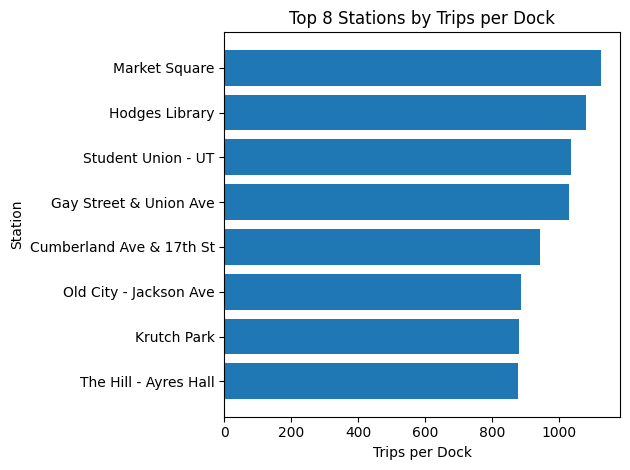

   cid         name     type  notnull dflt_value  pk
0    0  hour_of_day     TEXT        0       None   0
1    1   rider_type     TEXT        0       None   0
2    2        trips  INTEGER        0       None   0
   cid            name     type  notnull dflt_value  pk
0    0      station_id     TEXT        1       None   1
1    1    station_name     TEXT        1       None   0
2    2    neighborhood     TEXT        1       None   0
3    3           docks  INTEGER        1       None   0
4    4           trips  INTEGER        1       None   0
5    5  trips_per_dock     REAL        1       None   0


In [17]:
# TODO 8a: one parameterized query string, called twice with different params

station_date_query = """
    SELECT COUNT(*) AS trip_count
    FROM trips
    WHERE start_station_id = ?
      AND start_time >= ?
      AND start_time < ?
"""

s11_october = pd.read_sql(
    station_date_query,
    con,
    params=("S11", "2025-10-01", "2025-11-01")
)
print(s11_october)

s06_december = pd.read_sql(
    station_date_query,
    con,
    params=("S06", "2025-12-01", "2026-01-01")
)
print(s06_december)

# TODO 8b: top 8 by trips_per_dock -> labeled horizontal bar chart

top_stations = pd.read_sql("""
    SELECT station_name, trips_per_dock
    FROM station_summary_2025
    ORDER BY trips_per_dock DESC
    LIMIT 8
""", con)

top_stations = top_stations.sort_values("trips_per_dock")

plt.barh(top_stations["station_name"], top_stations["trips_per_dock"])
plt.title("Top 8 Stations by Trips per Dock")
plt.xlabel("Trips per Dock")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

# TODO 8c: hourly profile query -> to_sql("hourly_profile") -> compare both PRAGMA table_info outputs

hourly_profile = pd.read_sql("""
    SELECT
        strftime('%H', start_time) AS hour_of_day,
        rider_type,
        COUNT(*) AS trips
    FROM trips
    GROUP BY strftime('%H', start_time), rider_type
""", con)

hourly_profile.to_sql(
    "hourly_profile",
    con,
    if_exists="replace",
    index=False
)

print(pd.read_sql("PRAGMA table_info(hourly_profile)", con))
print(pd.read_sql("PRAGMA table_info(station_summary_2025)", con))


**Q8d:** *(Compare the PRAGMA table_info output for each column’s name, type, notnull, and primary-key indicator. hourly_profile is created by to_sql(), so it has inferred column types and no constraints like the manually defined station_summary_2025. PRAGMA table_info does not show foreign-key or CHECK constraints; it shows the column-level metadata. The warning is that to_sql() creates a convenient table, but does not reproduce a carefully constrained schema.)**

**Q8e:** *(The trips table has 250,000 rows, so SELECT * FROM trips transfers all of them to Python just to aggregate and display eight stations. Aggregating in SQL sends back only the top-eight result, reducing unnecessary data transfer and Python-side work.)**

**Q8f:** *(An f-string can produce a bug if values need quoting or escaping correctly, and it can expose the query to SQL injection if a value contains malicious SQL. ? placeholders bind values separately from the SQL, avoiding those problems.)**

---
## Reflection + AI Disclosure (5 pts)

**R1.** This week you ran statements that change data permanently. Describe
one moment in this assignment where you were about to run something and
stopped to check first — what you checked, and what you found. If it never
happened, say so honestly and name the task where it *should* have.

**R2.** Parts 2 and 4 offer two different answers to the same problem: fix
the mess with an `UPDATE`, or refuse it with a constraint. In 2–3 sentences,
say which one you would put in front of the Ride Knox data team first, and
why the other one alone would not be enough.

**R3.** **AI disclosure:** describe any use of generative AI tools in this
assignment, or state "No generative AI tools were used." Example: *"I used a
generative AI tool to explain why my composite index was ignored when I
filtered on the second column. All final statements, results, and
conclusions are my own."*

**R1:** *(Before changing `rider_type`, I checked the trip table row count and how many DISTINCT `rider-type` spellings it contained. The query showed 250,000 trips and six spellings, which gave a baseline to compare against after the updates.)**

**R2:** *(I would put a constraint in front of the data team first, because it prevents invalid values from being added again. An UPDATE can clean up the existing values, but it does not stop the same mess from returning and the constraint alone also would not standardize the existing values.)**

**R3:** *(I used Copilot in VSCode to suggest some query structures based on class presentations. I reviewed the suggestions to create my own codes such that the final work reflects my own review and decisions.)**

---
## Part 9 — Challenge (optional, +5 extra credit)

The data team liked `dock_changes` and wants it to be more than a filing
cabinet.

**9a.** Backfill the table so it holds a second row: the `S07` expansion from
Part 2 (12 docks to 16, effective `'2026-07-01'`), this time supplying an
explicit `reason` of your own. Then write **one** query that joins
`dock_changes` to `stations` and returns, per change: the station name, the
neighborhood, the date, the before and after counts, and the **percentage
increase** in capacity, rounded to 1 decimal.

**9b.** Use the history to do what Part 2 made impossible. Write one query
against `station_summary_2025` and `dock_changes` that returns, for each
station that has a recorded change: its stored `trips_per_dock` (computed on
the **new** dock count) and what that figure **would have been** on the
`docks_before` count. Show both numbers side by side.

**Q9c:** Your 9b output has two defensible pressure figures for the same
station and the same trips. Say which one belongs in a report about **2025
ridership** and which belongs in a report about **2026 capacity planning**,
and give the one-line caption you would put under each so a reader cannot
confuse them.

In [18]:
# TODO 9a: backfill the S07 change, then join dock_changes to stations with a % increase

insert_s07_change = run("""
    INSERT INTO dock_changes
        (station_id, effective_date, docks_before, docks_after, reason)
    VALUES
        ('S07', '2026-07-01', 12, 16, 'Greenway expansion')
""")
print("Rows inserted:", insert_s07_change)

dock_change_report = pd.read_sql("""
    SELECT
        s.station_name,
        s.neighborhood,
        d.effective_date,
        d.docks_before,
        d.docks_after,
        ROUND(
            (d.docks_after - d.docks_before) * 100.0 / d.docks_before,
            1
        ) AS percentage_increase
    FROM dock_changes AS d
    JOIN stations AS s
        ON s.station_id = d.station_id
""", con)
print(dock_change_report)

# TODO 9b: stored trips_per_dock vs. what it would have been on docks_before

pressure_comparison = pd.read_sql("""
    SELECT
        s.station_name,
        ss.trips_per_dock AS trips_per_dock_new_capacity,
        ROUND(ss.trips * 1.0 / d.docks_before, 1)
            AS trips_per_dock_before_expansion
    FROM station_summary_2025 AS ss
    JOIN dock_changes AS d
        ON d.station_id = ss.station_id
    JOIN stations AS s
        ON s.station_id = d.station_id
""", con)
print(pressure_comparison)

Rows inserted: 1
               station_name  neighborhood effective_date  docks_before  \
0  Cumberland Ave & 17th St  Fort Sanders     2026-07-01            16   
1     The Hill - Ayres Hall     UT Campus     2026-07-01            12   

   docks_after  percentage_increase  
0           20                 25.0  
1           16                 33.3  
               station_name  trips_per_dock_new_capacity  \
0  Cumberland Ave & 17th St                        943.7   
1     The Hill - Ayres Hall                        880.1   

   trips_per_dock_before_expansion  
0                           1179.6  
1                           1173.4  


**Q9c:** *(For a report about 2025 ridership, use the figure based on docks_before, since the expansion took effect in July 2026. For 2026 capacity planning, use the stored figure based on the expanded dock count.

2025 caption: “2025 trips per dock, using capacity before the July 2026 expansion.”
2026 caption: “2025 trips per dock, using capacity after the July 2026 expansion.”)**

---
## Before You Submit ✅

- [ ] **Kernel → Restart & Run All** — the working copy rebuilds from
      `ride_knox.db` and every cell runs top to bottom with no errors
- [ ] Every `# TODO` is completed and every **Q:** prompt is answered
- [ ] Your name and NetID are at the top
- [ ] Your anchors reconcile: **2** rider-type codes (158,542 / 91,458),
      **25** stations, **249,253** trips, **25** summary rows with one at **0**
- [ ] Every `UPDATE` and `DELETE` prints its **rows affected**, and Part 3's
      prediction is written in the comment
- [ ] All six `dock_changes` rules live in the `CREATE TABLE`, not in Python
- [ ] Part 7 shows a **plan and a time** for every before/after pair
- [ ] Part 8's chart has a title, an axis label, and readable station names
- [ ] Part 8a uses `?` placeholders with `params=` — no f-strings in any query
- [ ] `ride_knox.db` was never written to; all changes went to
      `ride_knox_work.db`
- [ ] Reflection + AI disclosure completed
- [ ] File saved and uploaded to Canvas as `.ipynb`